In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import snowflake.connector


In [ ]:
from getpass import getpass

conn = snowflake.connector.connect(
    ACCOUNT=your_account
    USER=your_username
    PASSWORD=your_password
    WAREHOUSE=your_warehouse
    DATABASE=your_database
    SCHEMA=your_schema 
)

print("Snowflake connected successfully!")

c:\Users\chira\AppData\Local\Programs\Python\Python314\Lib\site-packages\snowflake\connector\connection\_connection.py:135: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


Snowflake connected successfully!


In [4]:
query = '''Select 
    origin_country,
    count(*) as Total_Aircraft
from flight_tracking
where on_ground=False
group by origin_country
order by Total_Aircraft DESC
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,TOTAL_AIRCRAFT
0,United States,6191
1,Canada,412
2,United Kingdom,356
3,Turkey,301
4,Ireland,240
5,Malta,208
6,Germany,188
7,Spain,154
8,France,143
9,United Arab Emirates,130


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\1389614158.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


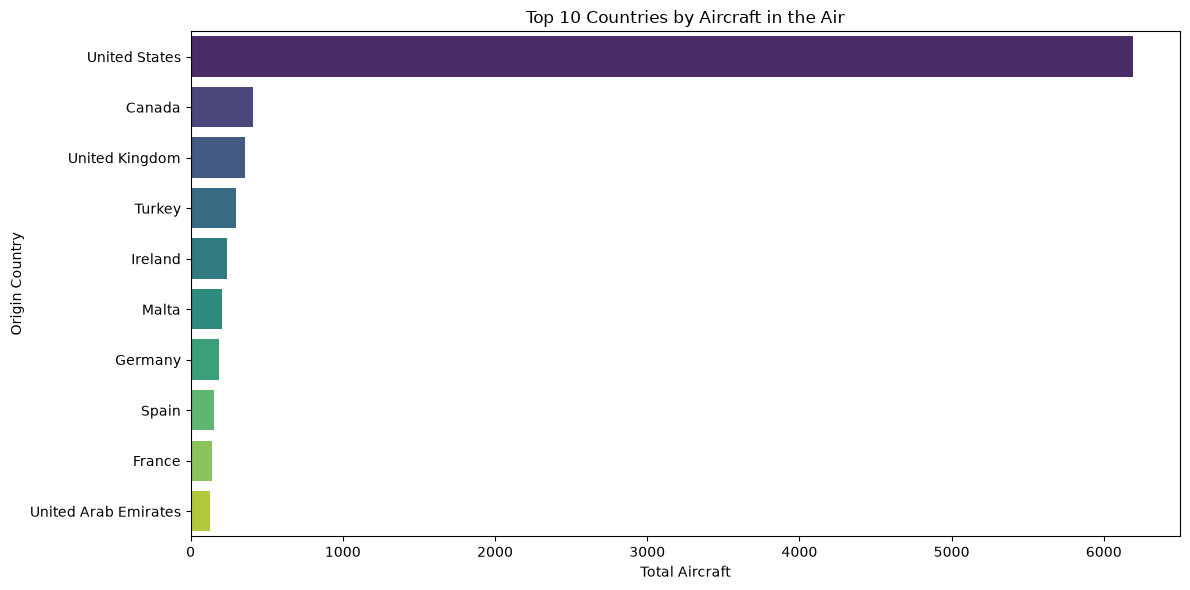

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='TOTAL_AIRCRAFT',
    y='ORIGIN_COUNTRY',
    palette='viridis'
)

plt.title('Top 10 Countries by Aircraft in the Air')
plt.xlabel('Total Aircraft')
plt.ylabel('Origin Country')

plt.tight_layout()
plt.show()

In [7]:
query = '''Select 
     origin_country,
     round(avg(velocity),2) as Average_speed
from flight_tracking
where on_ground=False
group by origin_country
order by Average_speed DESC
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,AVERAGE_SPEED
0,Lao People's Democratic Republic,288.51
1,Barbados,285.70
2,Bangladesh,273.15
3,Sweden,268.72
4,Taiwan,267.94
5,Kenya,255.87
6,Japan,252.76
7,Sri Lanka,252.27
8,Dominican Republic,252.24
9,Trinidad and Tobago,250.58


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\308988588.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


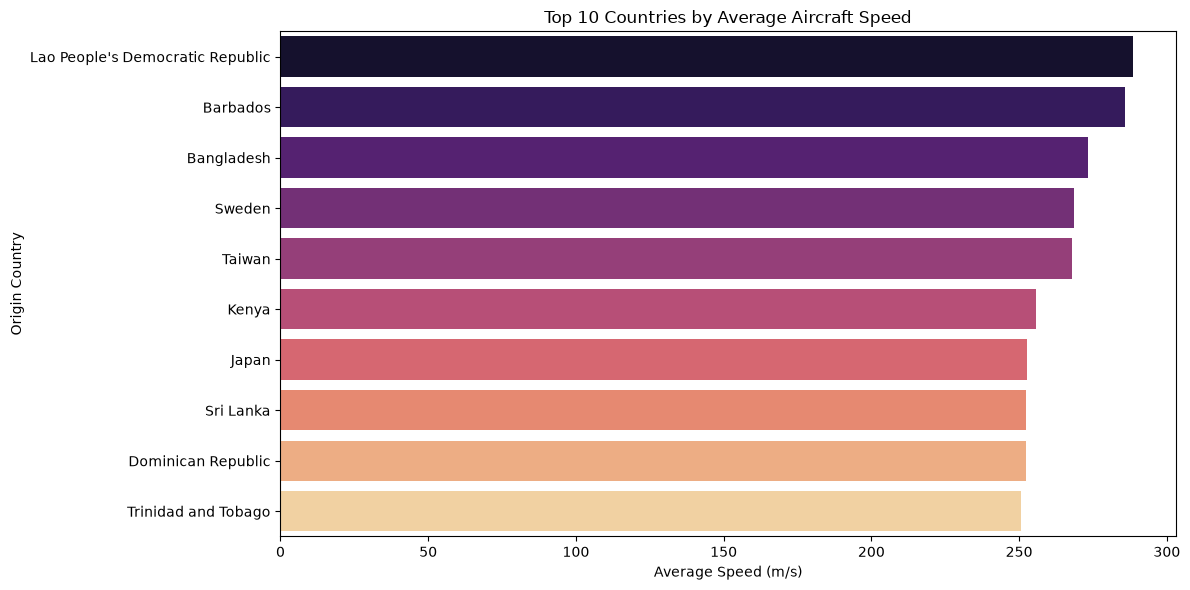

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='AVERAGE_SPEED',
    y='ORIGIN_COUNTRY',
    palette='magma'
)

plt.title('Top 10 Countries by Average Aircraft Speed')
plt.xlabel('Average Speed (m/s)')
plt.ylabel('Origin Country')

plt.tight_layout()
plt.show()

In [9]:
query = '''Select 
     origin_country,
     count(*) as Total_number
from flight_tracking
where on_ground=True
group by origin_country
order by Total_number DESC
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,TOTAL_NUMBER
0,United States,599
1,Canada,64
2,United Kingdom,28
3,Australia,21
4,Ireland,19
5,Germany,19
6,Malta,18
7,Spain,16
8,France,15
9,Japan,13


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\275070198.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


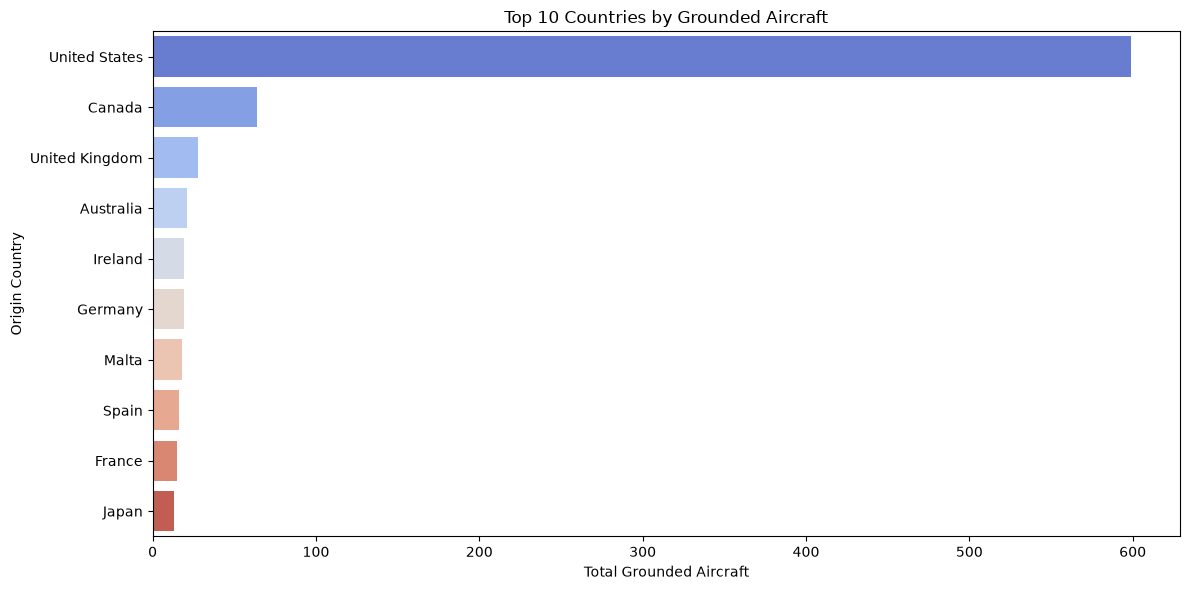

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='TOTAL_NUMBER',
    y='ORIGIN_COUNTRY',
    palette='coolwarm'
)

plt.title('Top 10 Countries by Grounded Aircraft')
plt.xlabel('Total Grounded Aircraft')
plt.ylabel('Origin Country')

plt.tight_layout()
plt.show()

In [11]:
query = '''Select 
    origin_country,
    round(avg(baro_altitude),2) as Avg_altitude
from flight_tracking
Where baro_altitude is not null and on_ground=false
group by origin_country
order by Avg_altitude DESC
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,AVG_ALTITUDE
0,Barbados,13716.00
1,Dominican Republic,12630.15
2,Venezuela,11582.40
3,Lao People's Democratic Republic,11308.08
4,Cape Verde,11277.60
5,Nepal,11277.60
6,Trinidad and Tobago,11277.60
7,Brunei Darussalam,11254.74
8,Bangladesh,11074.40
9,Kenya,10871.20


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\3243332927.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


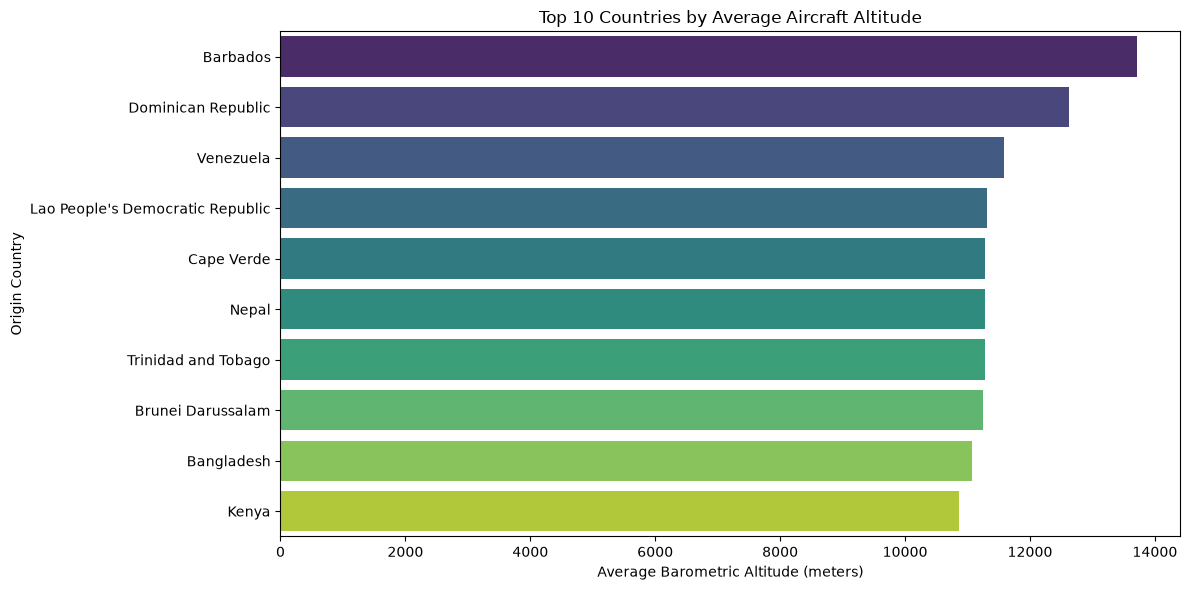

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='AVG_ALTITUDE',
    y='ORIGIN_COUNTRY',
    palette='viridis'
)

plt.title('Top 10 Countries by Average Aircraft Altitude')
plt.xlabel('Average Barometric Altitude (meters)')
plt.ylabel('Origin Country')

plt.tight_layout()
plt.show()

In [13]:
query = '''Select 
    icao24,
    callsign,
    origin_country,
    round(velocity*3.6,2) as Velocity_in_Km
from flight_tracking
where velocity is not null and on_ground=FALSE
order by velocity DESC
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ICAO24,CALLSIGN,ORIGIN_COUNTRY,VELOCITY_IN_KM
0,4ac9f8,SAS2860,Sweden,7521.05
1,4a91f9,SAS2822,Sweden,7176.24
2,48c231,RYR9719,Poland,4019.11
3,502d88,AUA1401,Latvia,3288.24
4,4baa56,THY217,Turkey,3209.44
5,4baa4f,THY489,Turkey,3199.10
6,471f9e,WZZ50ML,Hungary,3073.10
7,4ba8f5,TKJ2HX,Turkey,1988.03
8,4ba905,TKJ8RG,Turkey,1949.83
9,471fa7,WZZ82EK,Hungary,1924.38


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\480458381.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


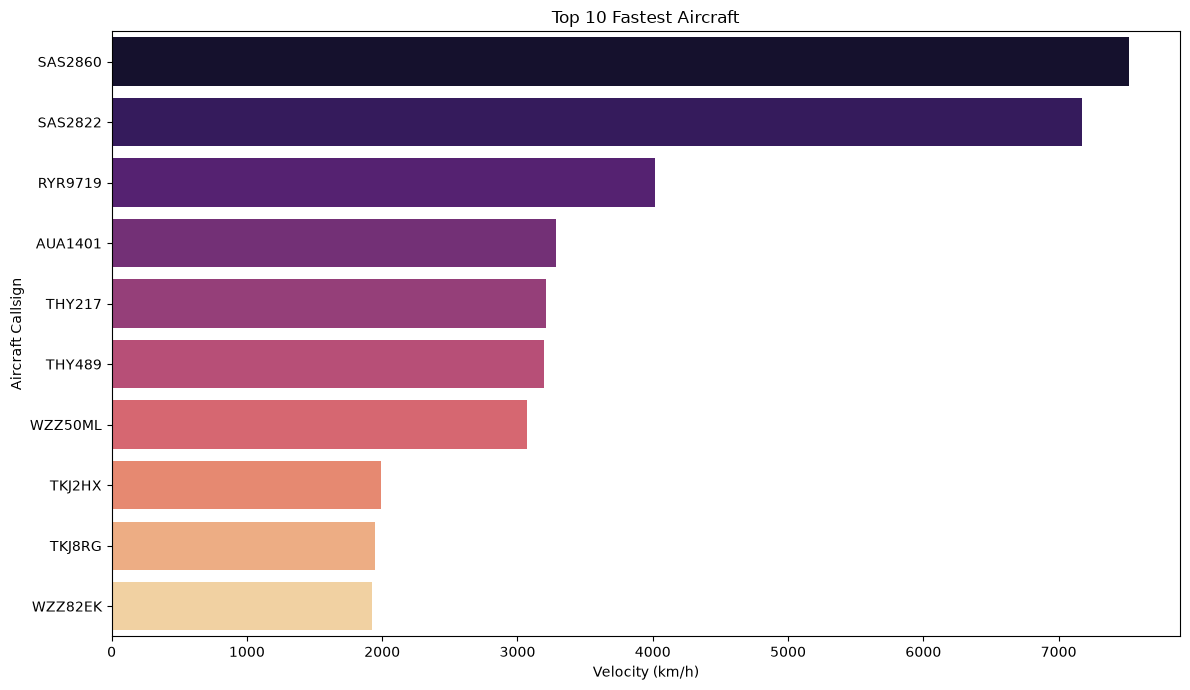

In [14]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df,
    x='VELOCITY_IN_KM',
    y='CALLSIGN',
    palette='magma'
)

plt.title('Top 10 Fastest Aircraft')
plt.xlabel('Velocity (km/h)')
plt.ylabel('Aircraft Callsign')

plt.tight_layout()
plt.show()

In [15]:
query = '''with flight_status as(
    select 
        icao24,
        on_ground
    from flight_tracking
),
status_count as(
    select 
        case 
            when on_ground=true then 'On Ground'
            when on_ground=false then 'Flying'
        end as Flight_Status,
        count(*) as Total_aircraft
    from flight_status
    group by Flight_Status
),
status_percentage as(
    select
        Flight_Status,
        Total_aircraft,
        round(
            (Total_aircraft*100.0/sum(Total_aircraft) over())
            ,2) as Percentage
    from status_count
)
SELECT * from status_percentage;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,FLIGHT_STATUS,TOTAL_AIRCRAFT,PERCENTAGE
0,Flying,10419,91.18
1,On Ground,1008,8.82


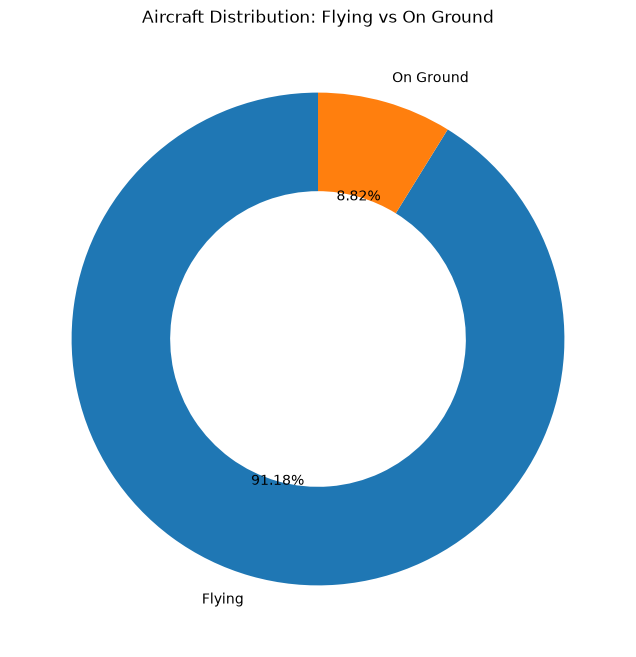

In [16]:
plt.figure(figsize=(8, 8))

plt.pie(
    df['TOTAL_AIRCRAFT'],
    labels=df['FLIGHT_STATUS'],
    autopct='%1.2f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Aircraft Distribution: Flying vs On Ground')

plt.show()

In [17]:
query = '''Select 
    origin_country,
    round(avg(velocity*3.6),2) as Avg_speed,
    count(*) as Total_aircraft
from flight_tracking
where on_ground=false
group by origin_country
having count(*)>100
order by Total_aircraft;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,AVG_SPEED,TOTAL_AIRCRAFT
0,Mexico,655.36,106
1,Austria,727.26,121
2,China,770.68,128
3,United Arab Emirates,804.74,130
4,France,672.24,143
5,Spain,728.71,154
6,Germany,714.27,188
7,Malta,733.50,208
8,Ireland,735.32,240
9,Turkey,785.82,301


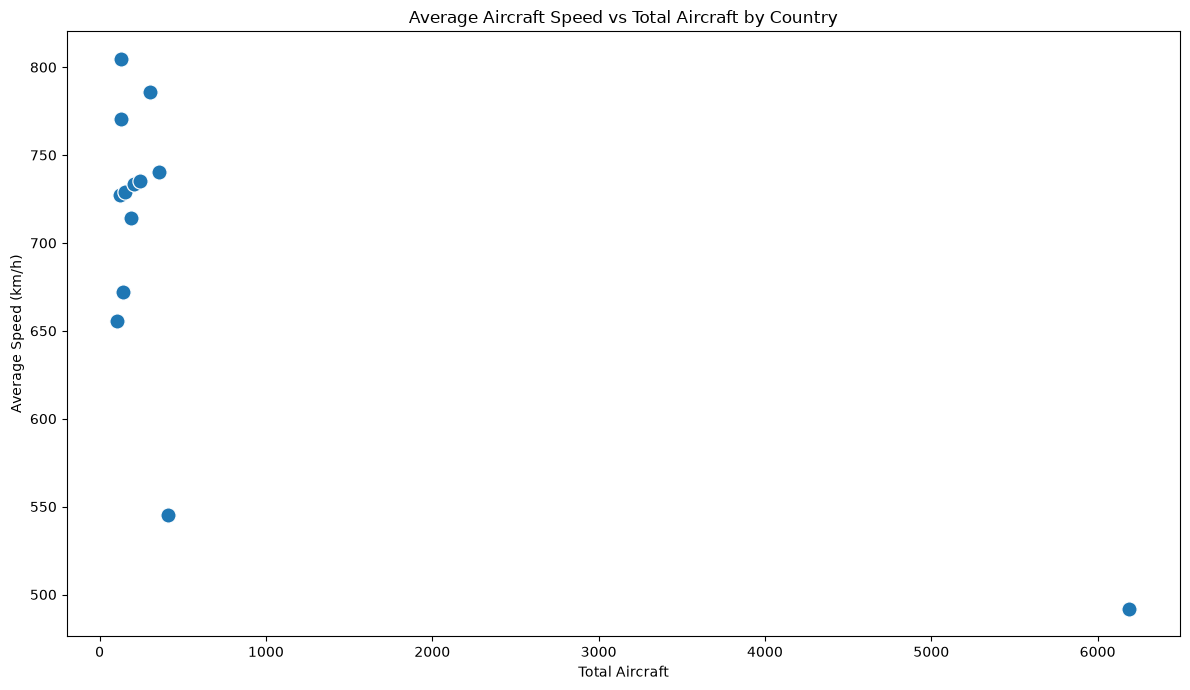

In [18]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='TOTAL_AIRCRAFT',
    y='AVG_SPEED',
    s=120
)

plt.title('Average Aircraft Speed vs Total Aircraft by Country')
plt.xlabel('Total Aircraft')
plt.ylabel('Average Speed (km/h)')

plt.tight_layout()
plt.show()

In [40]:
query = '''Select 
    origin_country,
    round(avg(velocity*3.6),2) as Average_velocity
from flight_tracking
where on_ground=false
group by origin_country
having Average_velocity>
(Select 
    avg(velocity*3.6)
from flight_tracking where on_ground=false);
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,AVERAGE_VELOCITY
0,India,755.09
1,France,672.24
2,United Kingdom,740.26
3,Estonia,734.38
4,Chile,725.23
5,Barbados,1028.52
6,Sweden,967.38
7,Turkey,785.82
8,Slovakia,709.70
9,Spain,728.71


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\1279991942.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  overall_avg = pd.read_sql_query("""
C:\Users\chira\AppData\Local\Temp\ipykernel_11020\1279991942.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


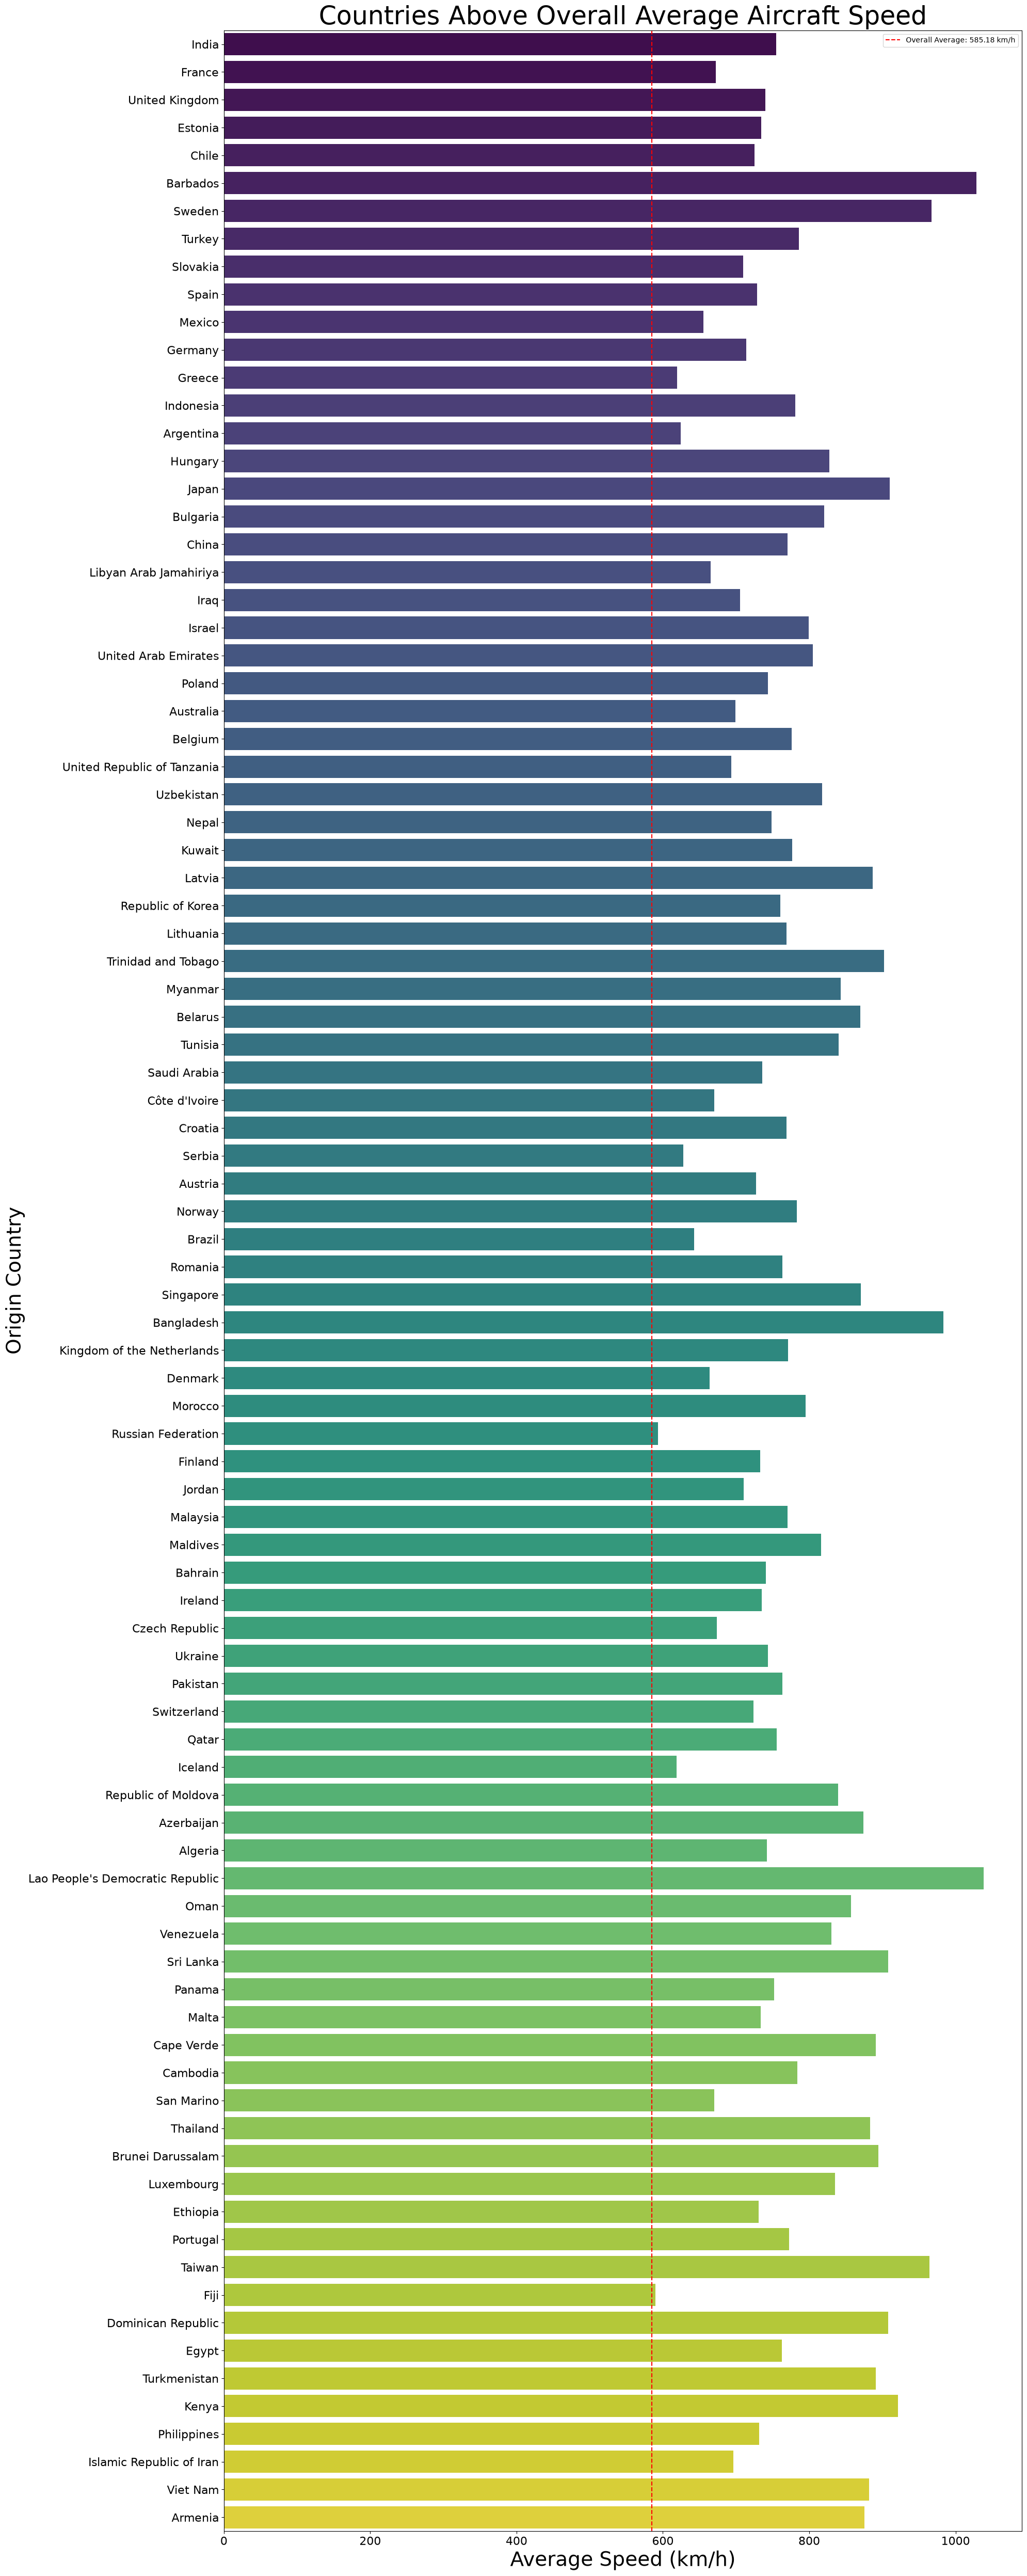

In [42]:
overall_avg = pd.read_sql_query("""
    SELECT AVG(velocity * 3.6) AS overall_avg
    FROM flight_tracking
    WHERE on_ground = FALSE
""", conn)

avg_speed = overall_avg['OVERALL_AVG'].iloc[0]

plt.figure(figsize=(20, 50))

sns.barplot(
    data=df,
    x='AVERAGE_VELOCITY',
    y='ORIGIN_COUNTRY',
    palette='viridis'
)

plt.axvline(
    x=avg_speed,
    linestyle='--',
    color='red',
    label=f'Overall Average: {avg_speed:.2f} km/h'
)

plt.title('Countries Above Overall Average Aircraft Speed', fontsize=35)
plt.xlabel('Average Speed (km/h)', fontsize=28)
plt.ylabel('Origin Country', fontsize=28)
plt.legend()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()

In [37]:
query = '''with total_aircraft as(Select 
    origin_country,
    count(*) as total_aircraft
from flight_tracking
group by origin_country
),
grounded_aircraft as(
    select 
        origin_country,
        count(*) as Grounded_aircraft
    from flight_tracking
    where on_ground=true
    group by origin_country
)
Select x.origin_country,round(coalesce(y.Grounded_aircraft,0)*100.0/total_aircraft,2) as Ground_percentage
from total_aircraft as x
left join grounded_aircraft as y
on x.origin_country = y.origin_country
where x.total_aircraft>=50
order by Ground_percentage DESC;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,GROUND_PERCENTAGE
0,Australia,24.14
1,Japan,22.41
2,Switzerland,14.29
3,Canada,13.45
4,Kingdom of the Netherlands,12.87
5,Singapore,12.07
6,India,10.84
7,France,9.49
8,Spain,9.41
9,Germany,9.18


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\2840421865.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


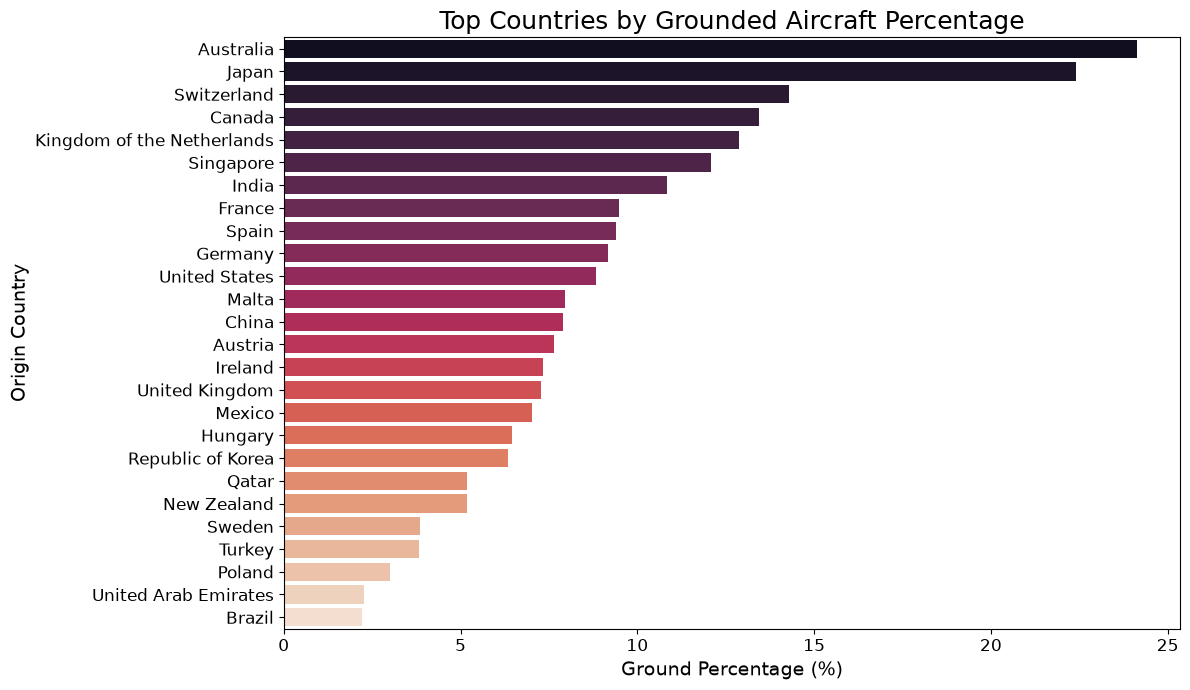

In [39]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df,
    x='GROUND_PERCENTAGE',
    y='ORIGIN_COUNTRY',
    palette='rocket'
)

plt.title(
    'Top Countries by Grounded Aircraft Percentage',
    fontsize=18
)

plt.xlabel('Ground Percentage (%)', fontsize=14)
plt.ylabel('Origin Country', fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

In [34]:
query = '''with total_aircraft as(select 
    origin_country,
    count(*) as total_aircraft
from flight_tracking
group by origin_country
)
select 
    origin_country,
    total_aircraft,
    sum(total_aircraft) over() as global_total_aircraft,
    round(total_aircraft*100.0/sum(total_aircraft) over(),2) as global_percentage
from total_aircraft
order by total_aircraft desc
limit 10;
'''
cursor = conn.cursor()

cursor.execute(query)

df = cursor.fetch_pandas_all()

cursor.close()

df.head(10)

,ORIGIN_COUNTRY,TOTAL_AIRCRAFT,GLOBAL_TOTAL_AIRCRAFT,GLOBAL_PERCENTAGE
0,United States,6790,11427,59.42
1,Canada,476,11427,4.17
2,United Kingdom,384,11427,3.36
3,Turkey,313,11427,2.74
4,Ireland,259,11427,2.27
5,Malta,226,11427,1.98
6,Germany,207,11427,1.81
7,Spain,170,11427,1.49
8,France,158,11427,1.38
9,China,139,11427,1.22


C:\Users\chira\AppData\Local\Temp\ipykernel_11020\3474883071.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


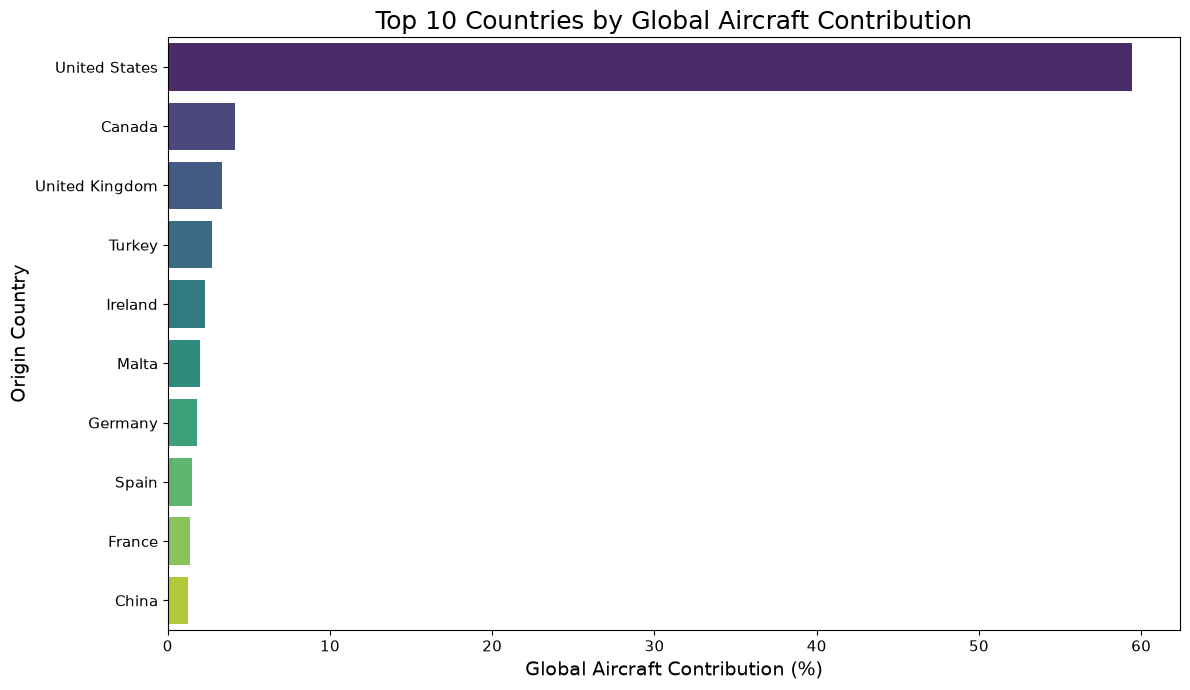

In [35]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df,
    x='GLOBAL_PERCENTAGE',
    y='ORIGIN_COUNTRY',
    palette='viridis'
)

plt.title(
    'Top 10 Countries by Global Aircraft Contribution',
    fontsize=18
)

plt.xlabel('Global Aircraft Contribution (%)', fontsize=14)
plt.ylabel('Origin Country', fontsize=14)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()